# Practice 2 — Advanced Extension

## E06 — AirPassengers SARIMA (exploratory draft)

Notebook này là exploratory draft, không phải execution evidence hoặc completion record.

### 1. Đọc và kiểm tra dữ liệu

In [1]:
import pandas as pd

from practice_2 import find_practice_root
from practice_2.visualization.table_style import style_table

PROJECT_ROOT = find_practice_root()
RAW_PATH = PROJECT_ROOT / "datasets" / "raw" / "airline-passengers.csv"


In [2]:

import pandas as pd
import matplotlib.pyplot as plt

# Đọc file dữ liệu
df = pd.read_csv(RAW_PATH)

# Chuyển Month sang datetime và đặt làm index
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").set_index("Month")

# Tạo chuỗi thời gian
series = df["Passengers"].astype(float).asfreq("MS")

# Kiểm tra dữ liệu
print(series.head())
print("Số quan sát:", len(series))
print("Giá trị thiếu:", series.isna().sum())
print("Thời gian:", series.index.min(), "đến", series.index.max())

Month
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS, Name: Passengers, dtype: float64
Số quan sát: 144
Giá trị thiếu: 0
Thời gian: 1949-01-01 00:00:00 đến 1960-12-01 00:00:00


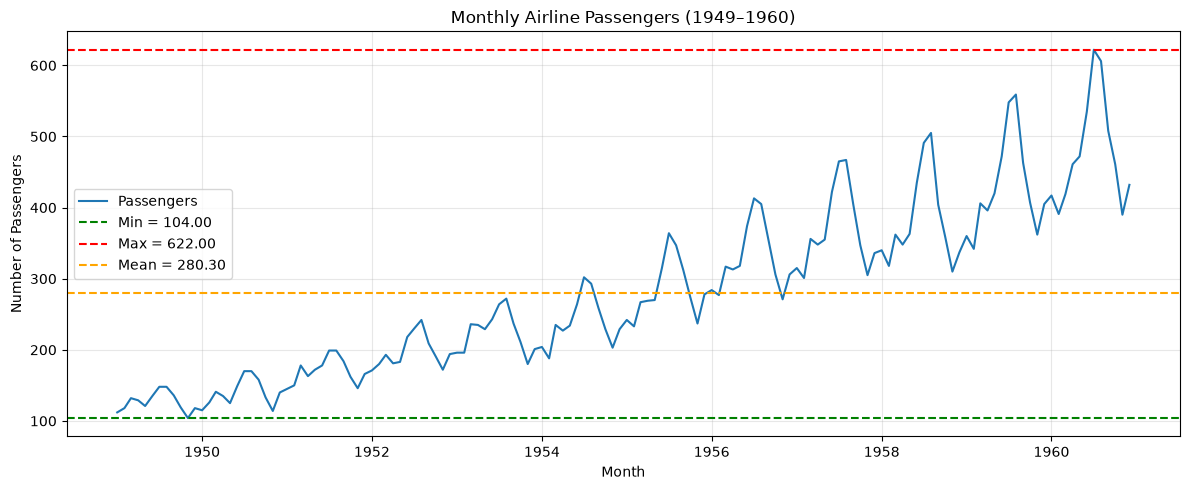

In [3]:
plt.figure(figsize=(12, 5))
# Vẽ chuỗi thời gian
plt.plot(series.index, series.values, label="Passengers")
# Tính các giá trị thống kê
min_value = series.min()
max_value = series.max()
mean_value = series.mean()
# Vẽ các đường ngang
plt.axhline(min_value, color="green", linestyle="--",
            label=f"Min = {min_value:.2f}")
plt.axhline(max_value, color="red", linestyle="--",
            label=f"Max = {max_value:.2f}")
plt.axhline(mean_value, color="orange", linestyle="--",
            label=f"Mean = {mean_value:.2f}")
plt.title("Monthly Airline Passengers (1949–1960)")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2. Chronological train/test split

In [4]:
n_train = int(len(series) * 0.8)
train_series = series.iloc[:n_train]
test_series = series.iloc[n_train:]

split_summary = pd.DataFrame({
    "Partition": ["Train", "Test"],
    "Observations": [len(train_series), len(test_series)],
    "Start": [train_series.index.min(), test_series.index.min()],
    "End": [train_series.index.max(), test_series.index.max()],
    "Status": ["Exploratory train", "Exploratory holdout"],
})

def highlight_exploratory(row):
    return ["background-color: #f1f5f9; color: #475569"] * len(row)

display(style_table(
    split_summary,
    caption="E06 — Chronological split (exploratory)",
    formats={"Observations": "{:,}", "Start": "{:%Y-%m}", "End": "{:%Y-%m}"},
    row_highlighter=highlight_exploratory,
))


Partition,Observations,Start,End,Status
Train,115,1949-01,1958-07,Exploratory train
Test,29,1958-08,1960-12,Exploratory holdout


### 3. Stationarity on the original series

In [5]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(series.dropna(), autolag="AIC")
adf_table = pd.DataFrame({
    "Series": ["Original series"],
    "ADF statistic": [adf_result[0]],
    "p-value": [adf_result[1]],
    "Critical value (5%)": [adf_result[4]["5%"]],
    "Status": ["Exploratory — not approved evidence"],
})
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:", adf_result[4]["5%"])
display(style_table(
    adf_table,
    caption="E06 — ADF on original series (exploratory)",
    formats={"ADF statistic": "{:.4f}", "p-value": "{:.6f}", "Critical value (5%)": "{:.4f}"},
    row_highlighter=highlight_exploratory,
))
if adf_result[1] < 0.05:
    print("Bác bỏ H0: Có bằng chứng chuỗi dừng.")
else:
    print("Chưa đủ bằng chứng bác bỏ H0: Chuỗi có thể không dừng.")


ADF Statistic: 0.8153688792060562
p-value: 0.9918802434376411
Critical Values: -2.8840418343195267


/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_67255/1406511901.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series.dropna(), autolag="AIC")


Series,ADF statistic,p-value,Critical value (5%),Status
Original series,0.8154,0.991880,-2.8840,Exploratory — not approved evidence


Chưa đủ bằng chứng bác bỏ H0: Chuỗi có thể không dừng.


### 4. Regular and seasonal differencing

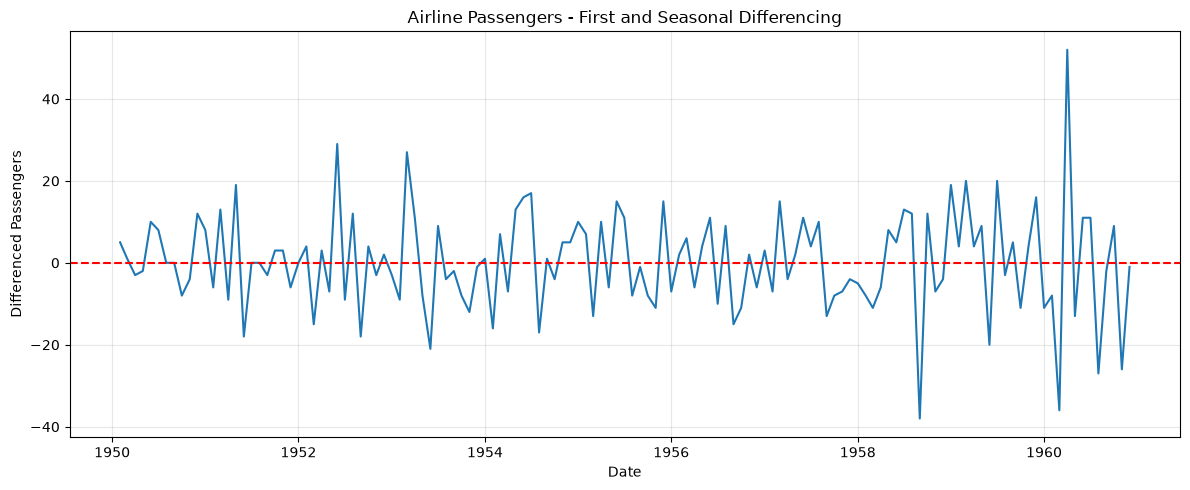

In [6]:
# Sai phân thường + mùa vụ 
series_combined_diff = series.diff().diff(12).dropna()

# Vẽ chuỗi sau sai phân kết hợp
plt.figure(figsize=(12, 5))
plt.plot(
    series_combined_diff.index,
    series_combined_diff.values
)
plt.axhline(0, color="red", linestyle="--")
plt.title("Airline Passengers - First and Seasonal Differencing")
plt.xlabel("Date")
plt.ylabel("Differenced Passengers")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5. Exploratory ADF retest

In [7]:
adf_diff = adfuller(series_combined_diff, autolag="AIC")
adf_diff_table = pd.DataFrame({
    "Series": ["Combined regular + seasonal difference"],
    "ADF statistic": [adf_diff[0]],
    "p-value": [adf_diff[1]],
    "Critical value (5%)": [adf_diff[4]["5%"]],
    "Status": ["Exploratory — not approved evidence"],
})
print("ADF Statistic:", adf_diff[0])
print("p-value:", adf_diff[1])
print("Critical Values:", adf_diff[4]["5%"])
display(style_table(
    adf_diff_table,
    caption="E06 — ADF after combined differencing (exploratory)",
    formats={"ADF statistic": "{:.4f}", "p-value": "{:.6f}", "Critical value (5%)": "{:.4f}"},
    row_highlighter=highlight_exploratory,
))
if adf_diff[1] < 0.05:
    print("Bác bỏ H0: Chuỗi sai phân kết hợp có bằng chứng dừng.")
else:
    print("Chưa đủ bằng chứng bác bỏ H0: Cần xem xét thêm.")


ADF Statistic: -15.595618083746334
p-value: 1.8565116001234692e-28
Critical Values: -2.8840418343195267


/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_67255/2869241319.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(series_combined_diff, autolag="AIC")


Series,ADF statistic,p-value,Critical value (5%),Status
Combined regular + seasonal difference,-15.5956,0.000000,-2.8840,Exploratory — not approved evidence


Bác bỏ H0: Chuỗi sai phân kết hợp có bằng chứng dừng.


### 6. Exploratory ACF/PACF

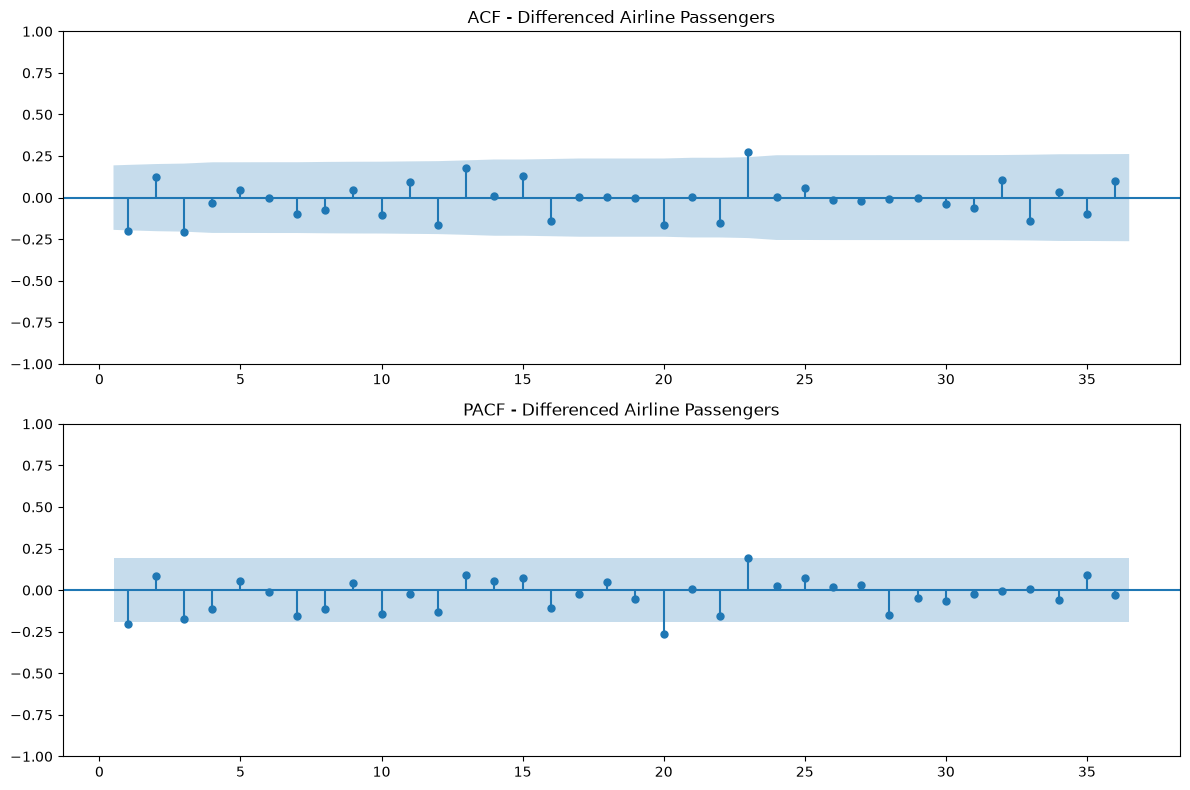

In [8]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

train_diff = train_series.diff().diff(12).dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(train_diff, lags=36, zero=False, ax=axes[0])
axes[0].set_title("ACF - Differenced Airline Passengers")

plot_pacf(
    train_diff,
    lags=36,
    zero=False,
    method="ywm",
    ax=axes[1]
)
axes[1].set_title("PACF - Differenced Airline Passengers")

plt.tight_layout()
plt.show()


### Exploratory differencing note

Các differencing settings dưới đây chỉ là exploratory choices trong notebook draft; chúng không phải approved E06 decision.

ACF/PACF observations dưới đây là exploratory và phải được xác nhận trên approved stationary transformed training series.

SARIMA candidates dưới đây là exploratory candidates, chưa được approval hoặc validation chính thức.

### 7. Exploratory SARIMA fitting

In [9]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd

# Khởi tạo danh sách lưu kết quả
sarima_results = {}

In [10]:
# Khởi tạo mô hình
sarima_1 = SARIMAX(
    train_series,
    order=(0, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Huấn luyện mô hình
sarima_result_1 = sarima_1.fit(disp=False)

# Lưu kết quả
sarima_results["SARIMA(0,1,1)(0,1,1,12)"] = sarima_result_1

# Hiển thị kết quả
print(sarima_result_1.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -326.671
Date:                            Wed, 25 Nov 2026   AIC                            659.342
Time:                                    13:59:02   BIC                            666.774
Sample:                                01-01-1949   HQIC                           662.336
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.1672      0.101     -1.659      0.097      -0.365       0.030
ma.S.L12      -0.1283      0.098   

In [11]:
# Khởi tạo mô hình
sarima_2 = SARIMAX(
    train_series,
    order=(1, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Huấn luyện mô hình
sarima_result_2 = sarima_2.fit(disp=False)

# Lưu kết quả
sarima_results["SARIMA(1,1,1)(0,1,1,12)"] = sarima_result_2

# Hiển thị kết quả
print(sarima_result_2.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -325.666
Date:                            Wed, 25 Nov 2026   AIC                            659.333
Time:                                    13:59:02   BIC                            669.242
Sample:                                01-01-1949   HQIC                           663.325
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6512      0.339     -1.920      0.055      -1.316       0.014
ma.L1          0.4706      0.381   

In [12]:
sarima_comparison = pd.DataFrame({
    "Model": list(sarima_results.keys()),
    "AIC": [result.aic for result in sarima_results.values()],
    "BIC": [result.bic for result in sarima_results.values()],
    "Status": "Exploratory fit — not approved selection",
})
display(style_table(
    sarima_comparison,
    caption="E06 — SARIMA in-sample comparison (exploratory)",
    formats={"AIC": "{:.2f}", "BIC": "{:.2f}"},
    row_highlighter=highlight_exploratory,
))


Model,AIC,BIC,Status
"SARIMA(0,1,1)(0,1,1,12)",659.34,666.77,Exploratory fit — not approved selection
"SARIMA(1,1,1)(0,1,1,12)",659.33,669.24,Exploratory fit — not approved selection


### 8. Forecast on the holdout

**Biểu đồ Forecast SARIMA(0,1,1)(0,1,1,12)**

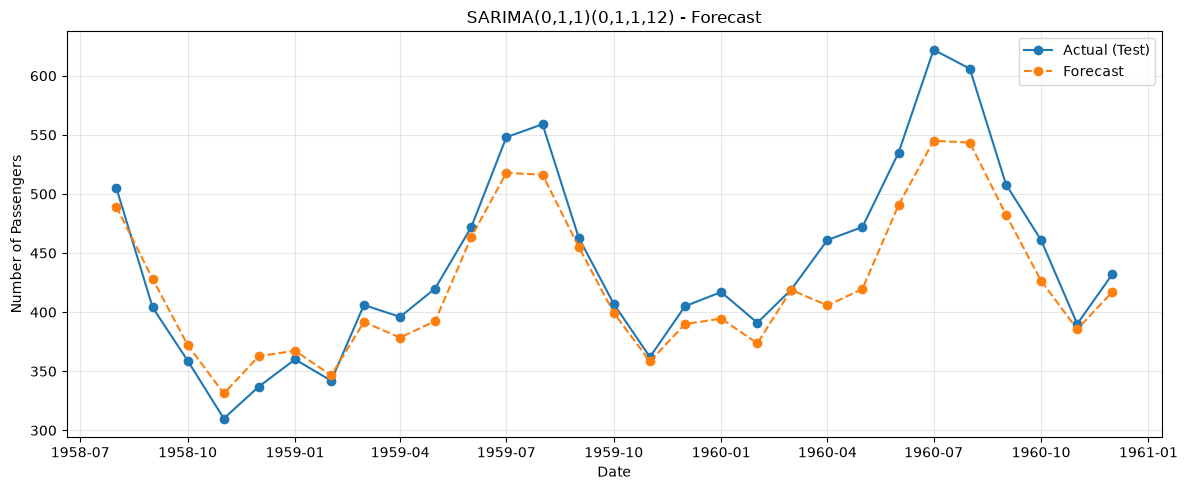

In [13]:
forecast_1 = sarima_result_1.forecast(steps=len(test_series))
plt.figure(figsize=(12, 5))

# Dữ liệu thực tế trên tập Test
plt.plot(
    test_series.index,
    test_series.values,
    label="Actual (Test)",
    marker="o"
)

# Giá trị dự báo
plt.plot(
    forecast_1.index,
    forecast_1.values,
    label="Forecast",
    linestyle="--",
    marker="o"
)

plt.title("SARIMA(0,1,1)(0,1,1,12) - Forecast")
plt.xlabel("Date")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Biểu đồ Forecast SARIMA(1,1,1)(0,1,1,12)**

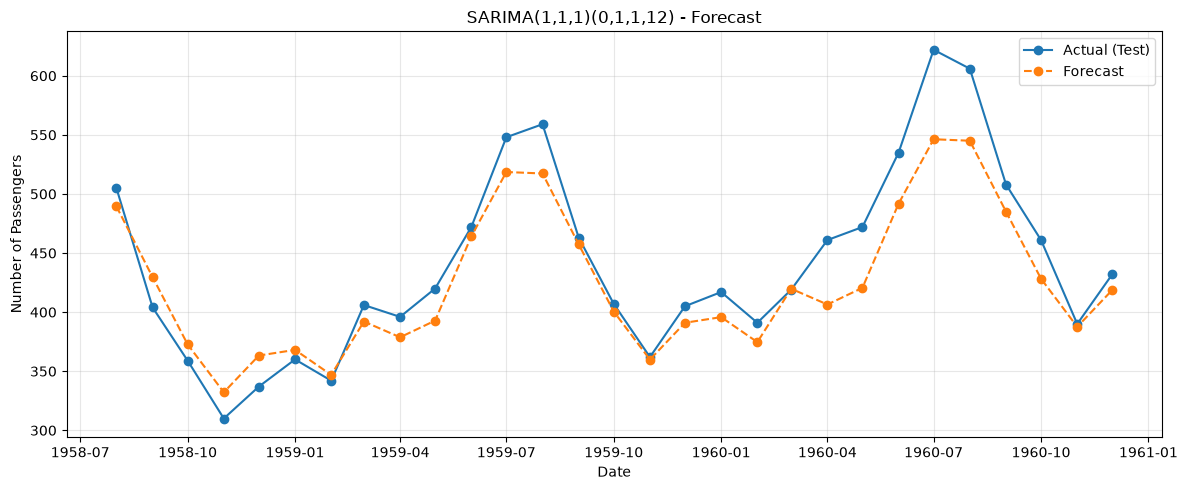

In [14]:
forecast_2 = sarima_result_2.forecast(steps=len(test_series))
plt.figure(figsize=(12, 5))

# Dữ liệu thực tế trên tập Test
plt.plot(
    test_series.index,
    test_series.values,
    label="Actual (Test)",
    marker="o"
)

# Giá trị dự báo
plt.plot(
    forecast_2.index,
    forecast_2.values,
    label="Forecast",
    linestyle="--",
    marker="o"
)

plt.title("SARIMA(1,1,1)(0,1,1,12) - Forecast")
plt.xlabel("Date")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 9. Exploratory metrics

In [15]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

forecast_1 = sarima_result_1.forecast(steps=len(test_series))
forecast_2 = sarima_result_2.forecast(steps=len(test_series))
mae_1 = mean_absolute_error(test_series, forecast_1)
rmse_1 = np.sqrt(mean_squared_error(test_series, forecast_1))
mae_2 = mean_absolute_error(test_series, forecast_2)
rmse_2 = np.sqrt(mean_squared_error(test_series, forecast_2))

evaluation = pd.DataFrame({
    "Model": [
        "SARIMA(0,1,1)(0,1,1,12)",
        "SARIMA(1,1,1)(0,1,1,12)"
    ],
    "MAE": [mae_1, mae_2],
    "RMSE": [rmse_1, rmse_2],
    "Status": "Exploratory holdout — validation pending",
})
display(style_table(
    evaluation,
    caption="E06 — Holdout metrics (exploratory; validation pending)",
    formats={"MAE": "{:.2f}", "RMSE": "{:.2f}"},
    row_highlighter=highlight_exploratory,
))


Model,MAE,RMSE,Status
"SARIMA(0,1,1)(0,1,1,12)",24.06,30.58,Exploratory holdout — validation pending
"SARIMA(1,1,1)(0,1,1,12)",23.37,29.92,Exploratory holdout — validation pending


Metrics legacy đã bị gỡ khỏi completion narrative. E06 chỉ được kết luận sau khi entry gate, approval, diagnostics và validation theo specification hoàn tất.